In [1]:
# CELL 2 - install + reproducibility header
!pip install -q diffusers peft accelerate transformers datasets imagehash lpips "torchmetrics[image]" torch-fidelity

import os, sys, json, time, io, gc, math, random, hashlib, platform, subprocess, shutil, textwrap, warnings
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import numpy as np, pandas as pd, torch
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 266
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEV = "cuda" if torch.cuda.is_available() else "cpu"
WDT = torch.float16 if DEV == "cuda" else torch.float32     # T4 has no bf16 -> fp16 weights + autocast
USE_AMP = (DEV == "cuda")

def _git(*a):
    r = subprocess.run(["git", "-C", os.environ.get("REPO_DIR", "/content/repo"), *a], capture_output=True, text=True)
    return r.stdout.strip() if r.returncode == 0 else None

print("commit  :", _git("rev-parse", "HEAD") or "n/a (repo not cloned - run Cell 1 or set REPO_DIR)")
print("dirty   :", bool(_git("status", "--porcelain")))
print("python  :", platform.python_version(), "|", platform.platform())
for p in ["torch", "torchvision", "diffusers", "transformers", "peft", "accelerate", "datasets",
          "huggingface_hub", "torchmetrics", "torch-fidelity", "lpips", "imagehash", "Pillow", "numpy"]:
    try: print(f"{p:16s}: {version(p)}")
    except PackageNotFoundError: print(f"{p:16s}: not installed")
if DEV == "cuda":
    pr = torch.cuda.get_device_properties(0)
    print(f"GPU     : {pr.name} | {pr.total_memory/2**30:.1f} GiB | capability {pr.major}.{pr.minor} | CUDA {torch.version.cuda}")
else:
    print("GPU     : NONE - switch the Colab runtime to T4 before training")
print("seed    :", SEED)

commit  : n/a (repo not cloned - run Cell 1 or set REPO_DIR)
dirty   : False
python  : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
torch           : 2.14.1+cu130
torchvision     : 0.29.1+cu130
diffusers       : 0.42.1
transformers    : 5.22.1
peft            : 0.21.2
accelerate      : 1.15.0
datasets        : 4.8.5
huggingface_hub : 1.33.0
torchmetrics    : 1.9.0
torch-fidelity  : 0.4.0
lpips           : 0.1.4
imagehash       : 4.3.2
Pillow          : 11.3.0
numpy           : 2.4.6
GPU     : Tesla T4 | 14.6 GiB | capability 7.5 | CUDA 13.0
seed    : 266


## Cell 3 — Config, folders, Hugging Face login
All knobs live here. Both fine-tuning runs share data, steps, batch size and LR; **only the LoRA rank differs** (a clean single-variable comparison).

In [7]:
# CELL 3 - config + folders + HF token  (LOCAL-FILES version: no Google Drive)
SEED = 266; set_seed(SEED)                                  # lab requires seed 266
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import shutil, glob
    WORK = Path("/content/p2_work"); WORK.mkdir(exist_ok=True)
    if not (WORK / "runs" / "run_a" / "train_stats.json").exists():     # restore the uploaded zip once; never overwrite newer results
        for zp in glob.glob("/content/data266_lab2_p2*.zip"):
            shutil.unpack_archive(zp, "/content/_unz")
        hit = next(Path("/content/_unz").rglob("runs"), None) if Path("/content/_unz").exists() else None
        if hit: shutil.copytree(hit.parent, WORK, dirs_exist_ok=True)
    print(sorted(str(p.relative_to(WORK)) for p in WORK.rglob("*") if p.is_file()))
    LOCAL = Path("/content/p2_local")                       # fast local scratch
else:
    WORK, LOCAL = Path("./p2_work"), Path("./p2_local")
for d in ["eval", "runs", "images", "grids", "human_eval"]:
    (WORK / d).mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)

CFG = dict(
    dataset_id = "lambdalabs/naruto-blip-captions",     # or "lambdalabs/pokemon-blip-captions"
    split = "train", image_col = "image", text_col = "text",
    base_model = "stable-diffusion-v1-5/stable-diffusion-v1-5",
    resolution = 512,
    seed = SEED,
    test_frac = 0.10,
    phash_max_dist = 2,          # near-duplicate threshold (64-bit pHash Hamming distance)
    clip_id = "openai/clip-vit-base-patch16",
)
RUNS = {   # same data, same steps, same LR - only the rank changes
    "run_a": dict(label="LoRA r=4",  rank=4,  alpha=4,  lr=1e-4),
    "run_b": dict(label="LoRA r=32", rank=32, alpha=32, lr=1e-4),
}
TRAIN = dict(max_steps=1500, batch_size=4, warmup_steps=50, weight_decay=1e-2,
             max_grad_norm=1.0, lr_scheduler="cosine", grad_checkpointing=True)
GEN = dict(steps=25, guidance=7.5, seeds=[0, 1])
FORCE_RETRAIN = False      # True = ignore saved adapters and retrain
HF_PRIVATE = True          # make public / share with instructor before submitting
HF_PREFIX  = "data266-lab2-p2"

def get_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)
HF_TOKEN = get_secret("HF_TOKEN")
print("HF_TOKEN:", "found" if HF_TOKEN else "NOT found -> Hugging Face pushes will be skipped")

json.dump(dict(CFG=CFG, RUNS=RUNS, TRAIN=TRAIN, GEN=GEN), open(WORK / "eval" / "p2_config.json", "w"), indent=1)
print(json.dumps(dict(CFG=CFG, RUNS=RUNS, TRAIN=TRAIN, GEN=GEN), indent=1))

['checkpoint/cache_train.pt', 'checkpoint/data_clean.zip', 'checkpoint/state.json', 'eval/p2_config.json', 'eval/p2_data_prep.json', 'eval/p2_prompts.json', 'runs/run_a/adapter/pytorch_lora_weights.safetensors', 'runs/run_a/train_stats.json']
HF_TOKEN: found
{
 "CFG": {
  "dataset_id": "lambdalabs/naruto-blip-captions",
  "split": "train",
  "image_col": "image",
  "text_col": "text",
  "base_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "resolution": 512,
  "seed": 266,
  "test_frac": 0.1,
  "phash_max_dist": 2,
  "clip_id": "openai/clip-vit-base-patch16"
 },
 "RUNS": {
  "run_a": {
   "label": "LoRA r=4",
   "rank": 4,
   "alpha": 4,
   "lr": 0.0001
  },
  "run_b": {
   "label": "LoRA r=32",
   "rank": 32,
   "alpha": 32,
   "lr": 0.0001
  }
 },
 "TRAIN": {
  "max_steps": 1500,
  "batch_size": 4,
  "warmup_steps": 50,
  "weight_decay": 0.01,
  "max_grad_norm": 1.0,
  "lr_scheduler": "cosine",
  "grad_checkpointing": true
 },
 "GEN": {
  "steps": 25,
  "guidance": 7.5,
  "s

## 2.1 Data preparation
Pipeline: **load → drop corrupted → resize to 512×512 → drop exact + near duplicates → NSFW filter → 90/10 split (seed 266)**.
Duplicates are removed *before* splitting so a near-copy cannot end up in both train and test.

In [ ]:
# CELL 4 - load dataset, print its license, drop corrupted records, resize+center-crop to 512x512
from datasets import load_dataset, Image as HFImage
from huggingface_hub import HfApi
from PIL import Image, ImageOps
import imagehash
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

R = CFG["resolution"]
ALL_DIR = LOCAL / "all"
shutil.rmtree(ALL_DIR, ignore_errors=True); ALL_DIR.mkdir(parents=True)

# --- dataset license (printed so it appears in the notebook output for the safety section)
DS_LICENSE = None
try:
    meta = HfApi().dataset_info(CFG["dataset_id"])
    card = meta.card_data.to_dict() if meta.card_data else {}
    DS_LICENSE = card.get("license")
    print("dataset      :", CFG["dataset_id"])
    print("license field:", DS_LICENSE if DS_LICENSE else "NOT DECLARED on the dataset card")
    print("license tags :", [t for t in (meta.tags or []) if t.startswith("license")])
except Exception as e:
    print("could not read dataset card:", repr(e))

ds = load_dataset(CFG["dataset_id"], split=CFG["split"])
ds = ds.cast_column(CFG["image_col"], HFImage(decode=False))      # decode ourselves so we can catch corrupt files
print(ds)

records, corrupted = [], []
for i, row in enumerate(tqdm(ds, desc="decode+resize")):
    try:
        raw = row[CFG["image_col"]]
        im = Image.open(io.BytesIO(raw["bytes"]) if raw.get("bytes") else raw["path"])
        im.load(); im = im.convert("RGB")
        cap = (row[CFG["text_col"]] or "").strip()
        if min(im.size) < 64: raise ValueError(f"tiny image {im.size}")
        if not cap:           raise ValueError("empty caption")
        sq = ImageOps.fit(im, (R, R), method=Image.BICUBIC, centering=(0.5, 0.5))   # center-crop + resize
    except Exception as e:
        corrupted.append(dict(idx=i, error=repr(e)[:120])); continue
    fn = f"{i:05d}.png"; sq.save(ALL_DIR / fn)
    records.append(dict(idx=i, file=fn, text=cap, orig_w=im.size[0], orig_h=im.size[1],
                        md5=hashlib.md5(sq.tobytes()).hexdigest(), phash=str(imagehash.phash(sq))))

df0 = pd.DataFrame(records)
FUNNEL = [("raw records", len(ds)), ("after dropping corrupted", len(df0))]
print(f"\nraw={len(ds)}  corrupted/invalid={len(corrupted)}  kept={len(df0)}")
if corrupted: print(pd.DataFrame(corrupted).head(10))
print("original size range (w x h): min", (df0.orig_w.min(), df0.orig_h.min()), " max", (df0.orig_w.max(), df0.orig_h.max()))

dataset      : lambdalabs/naruto-blip-captions
license field: NOT DECLARED on the dataset card
license tags : []


Repo card metadata block was not found. Setting CardData to empty.


Dataset({
    features: ['image', 'text'],
    num_rows: 1221
})


decode+resize:   0%|          | 0/1221 [00:00<?, ?it/s]


raw=1221  corrupted/invalid=0  kept=1221
original size range (w x h): min (124, 124)  max (3119, 3119)


In [ ]:
# CELL 5 - exact + near-duplicate removal (perceptual hash)
exact_mask = df0.duplicated("md5", keep="first")
n_exact = int(exact_mask.sum())
df1 = df0[~exact_mask].reset_index(drop=True)

bits = np.stack([imagehash.hex_to_hash(h).hash.flatten() for h in df1.phash]).astype(np.float32)
D = bits.shape[1] - (bits @ bits.T + (1 - bits) @ (1 - bits).T)          # pairwise Hamming distance
iu = np.triu_indices(len(D), k=1)
hist = np.bincount(D[iu].astype(int), minlength=10)[:10]
print("pairs by pHash Hamming distance (0..9):", dict(enumerate(hist.tolist())))
print("-> threshold used for 'near-duplicate': <=", CFG["phash_max_dist"], "(edit CFG['phash_max_dist'] and re-run if the examples below look wrong)")

keep, near_pairs = [], []
for i in range(len(df1)):
    if keep:
        j = keep[int(np.argmin(D[i, keep]))]
        if D[i, j] <= CFG["phash_max_dist"]:
            near_pairs.append((i, j, int(D[i, j]))); continue
    keep.append(i)
df2 = df1.iloc[keep].reset_index(drop=True)
n_near = len(near_pairs)

FUNNEL += [(f"after removing {n_exact} exact duplicates", len(df1)), (f"after removing {n_near} near-duplicates", len(df2))]
print(f"\nexact duplicates removed: {n_exact} | near-duplicates removed: {n_near} | remaining: {len(df2)}")

# eyeball check: top row = the image we kept, bottom row = the near-duplicate we dropped
show = near_pairs[:5]
if show:
    fig, ax = plt.subplots(2, len(show), figsize=(3 * len(show), 6.2), squeeze=False)
    for c, (i, j, dist) in enumerate(show):
        ax[0, c].imshow(Image.open(ALL_DIR / df1.file[j])); ax[0, c].set_title(f"kept (d={dist})", fontsize=9)
        ax[1, c].imshow(Image.open(ALL_DIR / df1.file[i])); ax[1, c].set_title("dropped", fontsize=9)
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()

# only now delete the files of removed images so nothing downstream can pick them up
for f in set(df0.file) - set(df2.file): (ALL_DIR / f).unlink(missing_ok=True)

pairs by pHash Hamming distance (0..9): {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0}
-> threshold used for 'near-duplicate': <= 2 (edit CFG['phash_max_dist'] and re-run if the examples below look wrong)

exact duplicates removed: 0 | near-duplicates removed: 0 | remaining: 1221


In [ ]:
# CELL 6 - NSFW filter on the training data (Stable Diffusion safety checker); flagged images are removed
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor

_sc = {}
def nsfw_flags(pil_images, bs=16):
    if "m" not in _sc:
        _sc["m"]  = StableDiffusionSafetyChecker.from_pretrained("CompVis/stable-diffusion-safety-checker").to(DEV).eval()
        _sc["fe"] = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")
    flags = []
    for i in range(0, len(pil_images), bs):
        batch = [im.convert("RGB").resize((R, R)) for im in pil_images[i:i + bs]]
        clip_in = _sc["fe"](batch, return_tensors="pt").pixel_values.to(DEV)
        arr = np.stack([np.asarray(im).astype(np.float32) / 255.0 for im in batch])     # checker blanks flagged ones in place; we only use the flags
        with torch.no_grad():
            _, has = _sc["m"](images=arr, clip_input=clip_in)
        flags += [bool(h) for h in has]
    return flags
def free_checker():
    _sc.clear(); gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()

flags = []
for i in tqdm(range(0, len(df2), 64), desc="NSFW check"):
    flags += nsfw_flags([Image.open(ALL_DIR / f) for f in df2.file[i:i + 64]])
df2["nsfw"] = flags
n_nsfw = int(df2.nsfw.sum())
print(f"flagged by safety checker: {n_nsfw} of {len(df2)}")
if n_nsfw:
    print("flagged captions (look for false positives on cartoon art):")
    print(df2[df2.nsfw].text.head(10).to_string())
df3 = df2[~df2.nsfw].reset_index(drop=True)
for f in df2[df2.nsfw].file: (ALL_DIR / f).unlink(missing_ok=True)
FUNNEL.append((f"after removing {n_nsfw} NSFW-flagged", len(df3)))
free_checker()

NSFW check:   0%|          | 0/20 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a differen

flagged by safety checker: 264 of 1221
flagged captions (look for false positives on cartoon art):
1     a man in a hoodie with a fire in the background
5                    a man in a blue and white outfit
9                    a man in a suit and a panda bear
12              a man with purple hair and green eyes
13                  a man with long hair and no shirt
15                a man in a green shirt with a sword
16      a man in a suit and tie looking at the camera
26                   a man with red hair and a hoodie
27                     a man with a sword in his hand
28              a woman with pink hair and green eyes


                            stage  images
                      raw records    1221
         after dropping corrupted    1221
after removing 0 exact duplicates    1221
 after removing 0 near-duplicates    1221
  after removing 264 NSFW-flagged     957
                      train (90%)     861
                       test (10%)      96


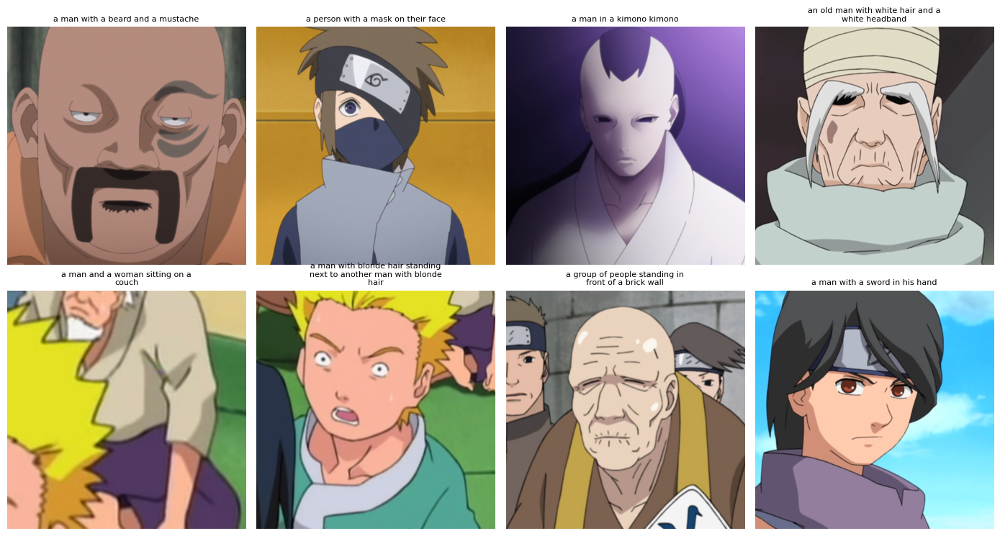

In [ ]:
# CELL 7 - 90/10 split with seed 266, write ImageFolder-style train/ and test/, print the data funnel
rng = np.random.default_rng(CFG["seed"])
perm = rng.permutation(len(df3))
n_test = int(round(CFG["test_frac"] * len(df3)))
df3["split"] = "train"; df3.loc[perm[:n_test], "split"] = "test"

for sp in ["train", "test"]:
    d = LOCAL / "data" / sp; shutil.rmtree(d, ignore_errors=True); d.mkdir(parents=True)
    with open(d / "metadata.jsonl", "w") as f:
        for _, r in df3[df3.split == sp].iterrows():
            shutil.copy(ALL_DIR / r.file, d / r.file)
            f.write(json.dumps({"file_name": r.file, "text": r.text}) + "\n")

N_TRAIN, N_TEST = int((df3.split == "train").sum()), int((df3.split == "test").sum())
FUNNEL += [("train (90%)", N_TRAIN), ("test (10%)", N_TEST)]
funnel_df = pd.DataFrame(FUNNEL, columns=["stage", "images"])
print(funnel_df.to_string(index=False))
assert N_TRAIN + N_TEST >= 500, "lab requires 500+ images"
json.dump(dict(funnel=FUNNEL, n_corrupted=len(corrupted), n_exact_dup=n_exact, n_near_dup=n_near, n_nsfw=n_nsfw,
               license=DS_LICENSE, train_idx=df3[df3.split == "train"].idx.tolist(), test_idx=df3[df3.split == "test"].idx.tolist()),
          open(WORK / "eval" / "p2_data_prep.json", "w"), indent=1)

# a look at the training data
tr = df3[df3.split == "train"].sample(8, random_state=SEED)
fig, ax = plt.subplots(2, 4, figsize=(14, 7.5))
for a, (_, r) in zip(ax.ravel(), tr.iterrows()):
    a.imshow(Image.open(LOCAL / "data" / "train" / r.file)); a.axis("off"); a.set_title(textwrap.fill(r.text, 34), fontsize=8)
plt.tight_layout(); plt.show()

## Fixed evaluation prompts
20 prompts: 10 in-domain, 5 out-of-domain, 5 compositional.

In [ ]:
# CELL 8 - the 20 fixed prompts (frozen before any tuning)
PROMPT_TEXT = {
  "in_domain": [
    "a cartoon character with blue hair and a sword",
    "a man with orange hair and a blue shirt",
    "a woman with long pink hair and a red dress",
    "a cartoon boy with spiky yellow hair and a forehead protector",
    "a cartoon character wearing a mask and a green vest",
    "an old man with white hair and a long beard",
    "a cartoon ninja standing on a rooftop at night",
    "a cartoon girl with glasses holding a book",
    "a cartoon character with red eyes and a black cloak",
    "a cartoon man with a scar on his face and a ponytail",
  ],
  "out_of_domain": [
    "a photograph of a red sports car parked on a city street",
    "a bowl of fresh fruit on a wooden table, studio lighting",
    "a golden retriever sitting on a sofa, photo",
    "the Eiffel Tower at sunset",
    "a modern kitchen interior with marble countertops",
  ],
  "compositional": [
    "a red cube on top of a blue sphere",
    "two cartoon characters, one with blue hair and one with red hair, standing back to back",
    "a cartoon cat wearing a tiny samurai helmet sitting next to a green teapot",
    "three ninjas on a rooftop, the left one holding a sword and the right one holding a scroll",
    "a cartoon character with a yellow hat riding a white horse in front of a mountain",
  ],
}
PROMPTS = []
for cat, lst in PROMPT_TEXT.items():
    for t in lst: PROMPTS.append(dict(id=len(PROMPTS) + 1, category=cat, prompt=t))
PROMPTS_BY_ID = {p["id"]: p for p in PROMPTS}
SEEDS = GEN["seeds"]
assert len(PROMPTS) == 20 and [len(v) for v in PROMPT_TEXT.values()] == [10, 5, 5]

train_caps = {json.loads(l)["text"].lower() for l in open(LOCAL / "data" / "train" / "metadata.jsonl")}
overlap = [p["prompt"] for p in PROMPTS if p["prompt"].lower() in train_caps]
print("prompts identical to a training caption (should be none):", overlap)

json.dump(dict(prompts=PROMPTS, seeds=SEEDS, num_inference_steps=GEN["steps"], guidance_scale=GEN["guidance"]),
          open(WORK / "eval" / "p2_prompts.json", "w"), indent=1)
print(pd.DataFrame(PROMPTS).to_string(index=False))
print("\n>>> copy", WORK / "eval" / "p2_prompts.json", "into repo eval/ and COMMIT before training <<<")

prompts identical to a training caption (should be none): ['a man with orange hair and a blue shirt']
 id      category                                                                                     prompt
  1     in_domain                                             a cartoon character with blue hair and a sword
  2     in_domain                                                    a man with orange hair and a blue shirt
  3     in_domain                                                a woman with long pink hair and a red dress
  4     in_domain                              a cartoon boy with spiky yellow hair and a forehead protector
  5     in_domain                                        a cartoon character wearing a mask and a green vest
  6     in_domain                                                an old man with white hair and a long beard
  7     in_domain                                             a cartoon ninja standing on a rooftop at night
  8     in_domain         

## 2.2 Fine-tuning
Two LoRA runs on the **same** cleaned train set, **same** steps / batch / LR / seed / noise stream — only the rank differs.
To make training fast and light on a T4, VAE latents and text embeddings are computed **once** (Cell 9); training then only touches the UNet.

In [ ]:
# CELL 9 - pre-compute VAE latents (mean/std) + CLIP text embeddings for the train set
from diffusers import AutoencoderKL
from transformers import CLIPTextModel, CLIPTokenizer

BASE  = CFG["base_model"]
CACHE = LOCAL / "cache_train.pt"
rows  = [json.loads(l) for l in open(LOCAL / "data" / "train" / "metadata.jsonl")]

tok = CLIPTokenizer.from_pretrained(BASE, subfolder="tokenizer")
te  = CLIPTextModel.from_pretrained(BASE, subfolder="text_encoder", torch_dtype=WDT).to(DEV).eval()
vae = AutoencoderKL.from_pretrained(BASE, subfolder="vae", torch_dtype=WDT).to(DEV).eval()

means, stds, embs = [], [], []
with torch.no_grad():
    for i in tqdm(range(0, len(rows), 16), desc="encode train set"):
        b = rows[i:i + 16]
        x = torch.stack([torch.from_numpy(np.asarray(Image.open(LOCAL / "data" / "train" / r["file_name"]).convert("RGB"))).permute(2, 0, 1)
                         for r in b]).to(DEV, WDT) / 127.5 - 1.0
        dist = vae.encode(x).latent_dist
        means.append(dist.mean.cpu()); stds.append(dist.std.cpu())
        ids = tok([r["text"] for r in b], padding="max_length", max_length=tok.model_max_length,
                  truncation=True, return_tensors="pt").input_ids.to(DEV)
        embs.append(te(ids)[0].cpu())
cache = dict(mean=torch.cat(means), std=torch.cat(stds), emb=torch.cat(embs),
             scaling=float(vae.config.scaling_factor), files=[r["file_name"] for r in rows])
torch.save(cache, CACHE)
print({k: (tuple(v.shape) if hasattr(v, "shape") else v if not isinstance(v, list) else len(v)) for k, v in cache.items()})

del vae, te, tok, cache, means, stds, embs
gc.collect()
if DEV == "cuda": torch.cuda.empty_cache()

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (5 outputs left out)

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

encode train set:   0%|          | 0/54 [00:00<?, ?it/s]

/tmp/ipykernel_7954/815735780.py:17: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.stack([torch.from_numpy(np.asarray(Image.open(LOCAL / "data" / "train" / r["file_name"]).convert("RGB"))).permute(2, 0, 1)


{'mean': (861, 4, 64, 64), 'std': (861, 4, 64, 64), 'emb': (861, 77, 768), 'scaling': 0.18215, 'files': 861}


In [11]:
# CELL 10 - training function (LoRA via PEFT, fp16 autocast + GradScaler, gradient checkpointing)
import torch.nn.functional as F
from diffusers import UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline
from diffusers.optimization import get_scheduler
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict

def train_run(name):
    rc = RUNS[name]; out = WORK / "runs" / name; (out / "adapter").mkdir(parents=True, exist_ok=True)
    weights, stats_path = out / "adapter" / "pytorch_lora_weights.safetensors", out / "train_stats.json"
    if weights.exists() and stats_path.exists() and not FORCE_RETRAIN:
        print(f"[{name}] adapter + stats already on disk -> skipping training (FORCE_RETRAIN=True to redo)")
        return json.load(open(stats_path))

    steps, bs = TRAIN["max_steps"], TRAIN["batch_size"]
    cache = torch.load(CACHE)
    mean, std, emb = (cache[k].to(DEV) for k in ("mean", "std", "emb")); scaling = cache["scaling"]; N = mean.shape[0]

    set_seed(SEED)                                    # identical noise/timestep stream for every run
    if DEV == "cuda":
        gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    unet = UNet2DConditionModel.from_pretrained(BASE, subfolder="unet", torch_dtype=WDT).to(DEV)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rc["rank"], lora_alpha=rc["alpha"], init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    params = [p for p in unet.parameters() if p.requires_grad]
    for p in params: p.data = p.data.float()          # trainable LoRA weights in fp32, frozen base stays fp16
    n_train = sum(p.numel() for p in params)
    n_base  = sum(p.numel() for p in unet.parameters()) - n_train
    if TRAIN["grad_checkpointing"]: unet.enable_gradient_checkpointing()
    unet.train()

    noise_sched = DDPMScheduler.from_pretrained(BASE, subfolder="scheduler")
    assert noise_sched.config.prediction_type == "epsilon"
    opt = torch.optim.AdamW(params, lr=rc["lr"], weight_decay=TRAIN["weight_decay"])
    sched = get_scheduler(TRAIN["lr_scheduler"], optimizer=opt, num_warmup_steps=TRAIN["warmup_steps"], num_training_steps=steps)
    scaler = torch.amp.GradScaler(DEV, enabled=USE_AMP)

    print(f"[{name}] {rc['label']} | trainable {n_train/1e6:.2f}M of {(n_train+n_base)/1e6:.1f}M params "
          f"({100*n_train/(n_train+n_base):.2f}%) | {N} train images | {steps} steps x batch {bs} = {steps*bs/N:.1f} epochs")
    g = torch.Generator().manual_seed(SEED)
    order, ptr, losses = torch.randperm(N, generator=g), 0, []
    if DEV == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    pbar = tqdm(range(steps), desc=name)
    for step in pbar:
        if ptr + bs > N: order, ptr = torch.randperm(N, generator=g), 0
        idx = order[ptr:ptr + bs].to(DEV); ptr += bs
        lat = (mean[idx] + std[idx] * torch.randn_like(std[idx])) * scaling       # sample from the VAE posterior
        noise = torch.randn_like(lat)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (bs,), device=DEV).long()
        noisy = noise_sched.add_noise(lat, noise, t)
        with torch.autocast(DEV, dtype=torch.float16, enabled=USE_AMP):
            pred = unet(noisy, t, encoder_hidden_states=emb[idx]).sample
        loss = F.mse_loss(pred.float(), noise.float())
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, TRAIN["max_grad_norm"])
        scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        losses.append(loss.item())
        if step % 10 == 0: pbar.set_postfix(loss=f"{np.mean(losses[-50:]):.4f}", lr=f"{sched.get_last_lr()[0]:.1e}")
    if DEV == "cuda": torch.cuda.synchronize()
    elapsed = time.time() - t0

    sd = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
    StableDiffusionPipeline.save_lora_weights(save_directory=str(out / "adapter"), unet_lora_layers=sd, safe_serialization=True)
    stats = dict(name=name, label=rc["label"], rank=rc["rank"], alpha=rc["alpha"], lr=rc["lr"], steps=steps, batch_size=bs,
                 epochs=steps * bs / N, n_train_images=N, trainable_params=n_train, base_unet_params=n_base,
                 trainable_pct=100 * n_train / (n_train + n_base),
                 peak_mem_allocated_gib=(torch.cuda.max_memory_allocated() / 2**30) if DEV == "cuda" else float("nan"),
                 peak_mem_reserved_gib=(torch.cuda.max_memory_reserved() / 2**30) if DEV == "cuda" else float("nan"),
                 train_seconds=elapsed, gpu_hours=elapsed / 3600, final_loss_avg100=float(np.mean(losses[-100:])),
                 gpu=torch.cuda.get_device_name(0) if DEV == "cuda" else "cpu", losses=losses)
    json.dump(stats, open(stats_path, "w"))
    del unet, opt, sched, scaler, mean, std, emb, cache
    gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()
    return stats

def show_stats(s): print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in s.items() if k != "losses"})

In [ ]:
# 1) stop peft from rejecting Colab's old torchao (we never use torchao)
import sys, gc, torch
try:
    from peft.import_utils import is_torchao_available as _chk; _chk()
except ImportError as _e:
    print("disabling torchao inside peft:", str(_e)[:90])
    for _n, _m in list(sys.modules.items()):
        if _n.startswith("peft") and hasattr(_m, "is_torchao_available"): _m.is_torchao_available = lambda: False

# 2) free the model left over from the failed attempt, so it doesn't inflate your peak-memory number
for _a in ("last_traceback", "last_value", "last_type", "last_exc"):
    if hasattr(sys, _a): setattr(sys, _a, None)
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory allocated now: {torch.cuda.memory_allocated()/2**30:.2f} GiB (should be ~0.00)")

disabling torchao inside peft: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.
GPU memory allocated now: 1.79 GiB (should be ~0.00)


In [ ]:
# CELL 11 - RUN A  (~45-60 min on a T4 at the default 1500 steps; watch the it/s and ETA in the first minute)
STATS = {}
STATS["run_a"] = train_run("run_a")
show_stats(STATS["run_a"])

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

[run_a] LoRA r=4 | trainable 0.80M of 860.3M params (0.09%) | 861 train images | 1500 steps x batch 4 = 7.0 epochs


run_a:   0%|          | 0/1500 [00:00<?, ?it/s]

{'name': 'run_a', 'label': 'LoRA r=4', 'rank': 4, 'alpha': 4, 'lr': 0.0001, 'steps': 1500, 'batch_size': 4, 'epochs': 6.9686, 'n_train_images': 861, 'trainable_params': 797184, 'base_unet_params': 859520964, 'trainable_pct': 0.0927, 'peak_mem_allocated_gib': 4.5952, 'peak_mem_reserved_gib': 4.791, 'train_seconds': 1824.647, 'gpu_hours': 0.5068, 'final_loss_avg100': 0.0859, 'gpu': 'Tesla T4'}


In [ ]:
# CELL 11b - SAVE A CHECKPOINT TO DRIVE
import shutil, json
from pathlib import Path
CK = WORK / "checkpoint"; CK.mkdir(parents=True, exist_ok=True)

# the adapter + stats are written to Drive by train_run itself - just confirm they are there
for n in RUNS:
    a = WORK / "runs" / n / "adapter" / "pytorch_lora_weights.safetensors"
    s = WORK / "runs" / n / "train_stats.json"
    print(f"{n}: adapter on Drive = {a.exists()} | stats on Drive = {s.exists()}")

# cleaned data (train/test images + captions) and the pre-computed latents, so Cells 4-9 never need re-running
shutil.make_archive(str(CK / "data_clean"), "zip", LOCAL / "data")
shutil.copy(CACHE, CK / "cache_train.pt")
json.dump(dict(N_TRAIN=N_TRAIN, N_TEST=N_TEST, n_exact=n_exact, n_near=n_near, n_nsfw=n_nsfw,
               n_corrupted=len(corrupted), DS_LICENSE=DS_LICENSE, FUNNEL=FUNNEL), open(CK / "state.json", "w"))
for f in sorted(CK.glob("*")): print(f"{f.name:18s} {f.stat().st_size / 2**20:8.1f} MB")
print("checkpoint saved ->", CK)

run_a: adapter on Drive = True | stats on Drive = True
run_b: adapter on Drive = False | stats on Drive = False
cache_train.pt        150.9 MB
data_clean.zip        202.6 MB
state.json              0.0 MB
checkpoint saved -> /content/drive/MyDrive/data266_lab2_p2/checkpoint


In [8]:
# CELL R (local-files version) - recover from the files you uploaded to /content/p2_work (NO Google Drive involved)
# Run Cell 2 and Cell 3 (the one with the unzip block) first, in this same runtime.
import shutil, json, gc, sys
from pathlib import Path
WORK = Path("/content/p2_work")                       # where your uploaded zip was unpacked
CK = WORK / "checkpoint"
need = [CK / "state.json", CK / "data_clean.zip", CK / "cache_train.pt", WORK / "eval" / "p2_prompts.json",
        WORK / "runs" / "run_a" / "train_stats.json", WORK / "runs" / "run_a" / "adapter" / "pytorch_lora_weights.safetensors"]
missing = [str(p.relative_to(WORK)) for p in need if not p.exists()]
assert not missing, f"missing under {WORK}: {missing}"
print("reading from:", WORK)

# 0) peft vs Colab's old torchao
try:
    from peft.import_utils import is_torchao_available as _chk; _chk()
except ImportError:
    for _n, _m in list(sys.modules.items()):
        if _n.startswith("peft") and hasattr(_m, "is_torchao_available"): _m.is_torchao_available = lambda: False

# 1) cleaned data + latents onto the local working disk
if not (LOCAL / "data" / "train" / "metadata.jsonl").exists():
    shutil.unpack_archive(str(CK / "data_clean.zip"), str(LOCAL / "data"))
BASE, R, CACHE = CFG["base_model"], CFG["resolution"], LOCAL / "cache_train.pt"
if not CACHE.exists(): shutil.copy(CK / "cache_train.pt", CACHE)

# 2) the small variables later cells use
st = json.load(open(CK / "state.json"))
N_TRAIN, N_TEST, n_exact, n_near, n_nsfw, DS_LICENSE = (st[k] for k in ("N_TRAIN", "N_TEST", "n_exact", "n_near", "n_nsfw", "DS_LICENSE"))
FUNNEL = [tuple(x) for x in st["FUNNEL"]]
corrupted = [None] * st["n_corrupted"]                  # later cells only use len(corrupted)

# 3) the frozen prompts exactly as saved before training
_p = json.load(open(WORK / "eval" / "p2_prompts.json"))
PROMPTS, SEEDS = _p["prompts"], _p["seeds"]
PROMPTS_BY_ID = {p["id"]: p for p in PROMPTS}

# 4) training results saved so far
STATS = {n: json.load(open(WORK / "runs" / n / "train_stats.json")) for n in RUNS if (WORK / "runs" / n / "train_stats.json").exists()}
print(f"restored: {N_TRAIN} train / {N_TEST} test images | {len(PROMPTS)} prompts | finished runs: {list(STATS)}")

# 5) imports + the NSFW-checker helpers that Cell 6 normally defines (needed again by Cell 24)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor
_sc = {}
def nsfw_flags(pil_images, bs=16):
    if "m" not in _sc:
        _sc["m"]  = StableDiffusionSafetyChecker.from_pretrained("CompVis/stable-diffusion-safety-checker").to(DEV).eval()
        _sc["fe"] = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")
    flags = []
    for i in range(0, len(pil_images), bs):
        batch = [im.convert("RGB").resize((R, R)) for im in pil_images[i:i + bs]]
        clip_in = _sc["fe"](batch, return_tensors="pt").pixel_values.to(DEV)
        arr = np.stack([np.asarray(im).astype(np.float32) / 255.0 for im in batch])
        with torch.no_grad():
            _, has = _sc["m"](images=arr, clip_input=clip_in)
        flags += [bool(h) for h in has]
    return flags
def free_checker():
    _sc.clear(); gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()

reading from: /content/p2_work
restored: 861 train / 96 test images | 20 prompts | finished runs: ['run_a']


In [9]:
assert STATS["run_a"]["n_train_images"] == N_TRAIN, "train set size differs from Run A - stop"
print("Run A trained on", STATS["run_a"]["n_train_images"], "images; Run B will use", N_TRAIN)
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/2**30:.2f} GiB (should be ~0.00)")

Run A trained on 861 images; Run B will use 861
GPU memory allocated: 0.00 GiB (should be ~0.00)


In [12]:
# CELL 12 - RUN B  (same data / steps / LR / seed, different rank)
STATS["run_b"] = train_run("run_b")
show_stats(STATS["run_b"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

[run_b] LoRA r=32 | trainable 6.38M of 865.9M params (0.74%) | 861 train images | 1500 steps x batch 4 = 7.0 epochs


run_b:   0%|          | 0/1500 [00:00<?, ?it/s]

{'name': 'run_b', 'label': 'LoRA r=32', 'rank': 32, 'alpha': 32, 'lr': 0.0001, 'steps': 1500, 'batch_size': 4, 'epochs': 6.9686, 'n_train_images': 861, 'trainable_params': 6377472, 'base_unet_params': 859520964, 'trainable_pct': 0.7365, 'peak_mem_allocated_gib': 2.8755, 'peak_mem_reserved_gib': 3.0742, 'train_seconds': 1752.4449, 'gpu_hours': 0.4868, 'final_loss_avg100': 0.0857, 'gpu': 'Tesla T4'}


           label rank alpha trainable_params trainable_pct      lr steps batch_size    epochs peak_mem_allocated_gib peak_mem_reserved_gib train_seconds gpu_hours final_loss_avg100       gpu
run_a   LoRA r=4    4     4           797184      0.092662  0.0001  1500          4  6.968641               4.595212              4.791016      1824.647  0.506846          0.085938  Tesla T4
run_b  LoRA r=32   32    32          6377472      0.736515  0.0001  1500          4  6.968641                2.87553              3.074219    1752.44488   0.48679          0.085725  Tesla T4


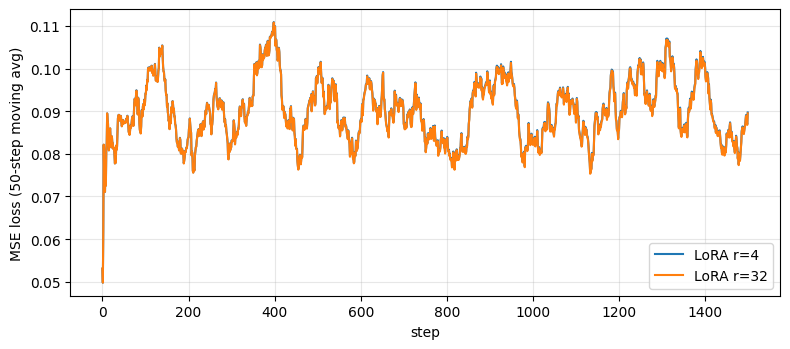

In [13]:
# CELL 13 - training summary table + loss curves  (this is the "report parameters, LR, steps, batch, peak memory, time" table)
STATS = {n: json.load(open(WORK / "runs" / n / "train_stats.json")) for n in RUNS}
cols = ["label", "rank", "alpha", "trainable_params", "trainable_pct", "lr", "steps", "batch_size", "epochs",
        "peak_mem_allocated_gib", "peak_mem_reserved_gib", "train_seconds", "gpu_hours", "final_loss_avg100", "gpu"]
train_tbl = pd.DataFrame({n: {c: STATS[n][c] for c in cols} for n in RUNS}).T
print(train_tbl.to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
for n in RUNS:
    ax.plot(pd.Series(STATS[n]["losses"]).rolling(50, min_periods=1).mean(), label=STATS[n]["label"])
ax.set_xlabel("step"); ax.set_ylabel("MSE loss (50-step moving avg)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(WORK / "grids" / "loss_curves.png", dpi=150); plt.show()

### Push both adapters to Hugging Face (with a model card)
The card is generated from the numbers above; Cell 26 regenerates it with the final evaluation results.

In [14]:
# CELL 14 - HF helpers + model card builder + first push (weights + basic card)
from huggingface_hub import HfApi
api = HfApi(token=HF_TOKEN) if HF_TOKEN else None
HF_USER = api.whoami()["name"] if api else None
print("HF user:", HF_USER)

def fmt(x, nd=4): return "n/a" if x is None or (isinstance(x, float) and math.isnan(x)) else (f"{x:.{nd}f}" if isinstance(x, float) else str(x))

def build_model_card(name):
    s, rc = STATS[name], RUNS[name]
    res = globals().get("RESULTS", {}).get(name)
    sf  = globals().get("SAFETY", {})
    repo = f"{HF_USER}/{HF_PREFIX}-{name}"
    L = ["---", "license: creativeml-openrail-m", f"base_model: {CFG['base_model']}", "library_name: diffusers",
         "pipeline_tag: text-to-image", "tags:", "- stable-diffusion", "- lora", "- text-to-image", "- diffusers",
         "datasets:", f"- {CFG['dataset_id']}", "---", "",
         f"# {HF_PREFIX}-{name}: {rc['label']} on {CFG['dataset_id'].split('/')[-1]}", "",
         "LoRA adapter for Stable Diffusion 1.5, trained for DATA 266 (Fall 2026) Lab 2, Part 2. "
         "A second adapter with a different rank was trained with identical data, steps, LR and seed for comparison.", "",
         "## Training data",
         f"- Dataset: `{CFG['dataset_id']}`; license on the dataset card: **{DS_LICENSE or 'not declared'}** (check terms before any reuse).",
         f"- After cleaning: **{N_TRAIN} train / {N_TEST} test** images, {CFG['resolution']}x{CFG['resolution']} (center crop), split seed {CFG['seed']}.",
         f"- Removed: {len(corrupted)} corrupted/invalid, {n_exact} exact duplicates, {n_near} near-duplicates (pHash <= {CFG['phash_max_dist']}), {n_nsfw} flagged by the SD safety checker.", "",
         "## Training procedure", "| item | value |", "|---|---|",
         f"| method | LoRA on UNet attention (to_q, to_k, to_v, to_out.0) |",
         f"| rank / alpha | {s['rank']} / {s['alpha']} |",
         f"| trainable parameters | {s['trainable_params']:,} ({s['trainable_pct']:.2f}% of UNet) |",
         f"| learning rate / schedule | {s['lr']} / {TRAIN['lr_scheduler']}, {TRAIN['warmup_steps']} warm-up steps |",
         f"| steps x batch | {s['steps']} x {s['batch_size']} ({s['epochs']:.1f} epochs) |",
         f"| precision | fp16 autocast, LoRA weights fp32, gradient checkpointing {TRAIN['grad_checkpointing']} |",
         f"| hardware | {s['gpu']} |",
         f"| peak GPU memory (allocated) | {fmt(s['peak_mem_allocated_gib'], 2)} GiB |",
         f"| train time | {s['train_seconds']/60:.1f} min ({s['gpu_hours']:.3f} GPU-hours) |",
         f"| seed | {SEED} |", ""]
    if res:
        L += ["## Evaluation (20 fixed prompts x seeds 0,1; computed in the training notebook)", "| metric | base SD1.5 | this model |", "|---|---|---|"]
        for k, v in res.items():
            if k in RESULTS["base"] and isinstance(v, float): L.append(f"| {k} | {fmt(RESULTS['base'][k])} | {fmt(v)} |")
        L.append("")
    if sf:
        L += ["## Safety checks", f"- Generated images flagged by the SD safety checker: {sf.get('nsfw_by_model', {}).get(name, 'n/a')} of {len(PROMPTS)*len(SEEDS)}.",
              f"- Memorization check: {sf.get('memorization_summary', {}).get(name, 'n/a')}", ""]
    L += ["## Usage", "```python", "import torch", "from diffusers import StableDiffusionPipeline",
          f"pipe = StableDiffusionPipeline.from_pretrained('{CFG['base_model']}', torch_dtype=torch.float16).to('cuda')",
          f"pipe.load_lora_weights('{repo}')", "image = pipe('a cartoon character with blue hair and a sword').images[0]", "```", "",
          "## Intended use and limitations",
          "- Course project / research on parameter-efficient fine-tuning; not for production use.",
          "- Trained on a small stylised dataset of copyrighted fan material: outputs imitate that style and may resemble source characters.",
          "- Out-of-domain prompts can pick up the training style (style bleed); compositional prompts (counts, attribute binding) remain unreliable.",
          "- Inherits all limitations and the CreativeML OpenRAIL-M license of Stable Diffusion 1.5.", ""]
    return "\n".join(L)

def push_model(name):
    if not api: print("no HF_TOKEN -> skipped"); return
    stage = LOCAL / "hf_stage" / name; shutil.rmtree(stage, ignore_errors=True); stage.mkdir(parents=True)
    shutil.copy(WORK / "runs" / name / "adapter" / "pytorch_lora_weights.safetensors", stage)
    (stage / "README.md").write_text(build_model_card(name))
    json.dump({k: v for k, v in STATS[name].items() if k != "losses"}, open(stage / "train_stats.json", "w"), indent=1)
    json.dump(STATS[name]["losses"], open(stage / "loss_per_step.json", "w"))
    json.dump(dict(RUN=RUNS[name], TRAIN=TRAIN, CFG=CFG), open(stage / "training_config.json", "w"), indent=1)
    repo = f"{HF_USER}/{HF_PREFIX}-{name}"
    api.create_repo(repo, repo_type="model", private=HF_PRIVATE, exist_ok=True)
    api.upload_folder(folder_path=str(stage), repo_id=repo, repo_type="model", commit_message=f"{name}: adapter + model card")
    print("pushed ->", f"https://huggingface.co/{repo}", "(private)" if HF_PRIVATE else "(public)")

for n in RUNS: push_model(n)

HF user: muhammadfsalman
pushed -> https://huggingface.co/muhammadfsalman/data266-lab2-p2-run_a (private)
pushed -> https://huggingface.co/muhammadfsalman/data266-lab2-p2-run_b (private)


## 2.3 Image generation
20 fixed prompts × seeds 0 and 1 = **40 images per model**, for the base model and both runs (120 images). Same sampler, steps and guidance everywhere; the same seed gives the same starting noise, so images are directly comparable.

In [15]:
# CELL 15 - generate 40 images for base, run_a, run_b
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
MODELS = ["base"] + list(RUNS)
MODEL_LABELS = {"base": "Base SD 1.5", **{n: RUNS[n]["label"] for n in RUNS}}

def load_pipe():
    pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=WDT, safety_checker=None, requires_safety_checker=False).to(DEV)
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    return pipe

GEN_TIMES_PATH = WORK / "images" / "gen_times.json"
GEN_TIMES = json.load(open(GEN_TIMES_PATH)) if GEN_TIMES_PATH.exists() else {}

def generate_set(pipe, model):
    out = WORK / "images" / model; out.mkdir(parents=True, exist_ok=True)
    todo = [(p, s) for p in PROMPTS for s in SEEDS if not (out / f"p{p['id']:02d}_s{s}.png").exists()]
    if not todo:
        print(f"{model}: all {len(PROMPTS)*len(SEEDS)} images already exist"); return
    if DEV == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for p, s in tqdm(todo, desc=model):
        g = torch.Generator(device=DEV).manual_seed(s)
        img = pipe(p["prompt"], num_inference_steps=GEN["steps"], guidance_scale=GEN["guidance"], height=R, width=R, generator=g).images[0]
        img.save(out / f"p{p['id']:02d}_s{s}.png")
    if DEV == "cuda": torch.cuda.synchronize()
    GEN_TIMES[model] = dict(sec_per_image=(time.time() - t0) / len(todo), n_timed=len(todo))
    json.dump(GEN_TIMES, open(GEN_TIMES_PATH, "w"), indent=1)

pipe = load_pipe()
generate_set(pipe, "base")
for name in RUNS:
    pipe.load_lora_weights(str(WORK / "runs" / name / "adapter"), weight_name="pytorch_lora_weights.safetensors", adapter_name=name)
    generate_set(pipe, name)
    pipe.unload_lora_weights()
del pipe; gc.collect()
if DEV == "cuda": torch.cuda.empty_cache()
print(json.dumps(GEN_TIMES, indent=1))

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

base:   0%|          | 0/40 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


run_a:   0%|          | 0/40 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


run_b:   0%|          | 0/40 [00:00<?, ?it/s]

{
 "base": {
  "sec_per_image": 4.329520165920258,
  "n_timed": 40
 },
 "run_a": {
  "sec_per_image": 4.536405581235885,
  "n_timed": 40
 },
 "run_b": {
  "sec_per_image": 4.533293002843857,
  "n_timed": 40
 }
}


{'base': 40, 'run_a': 40, 'run_b': 40} images per model


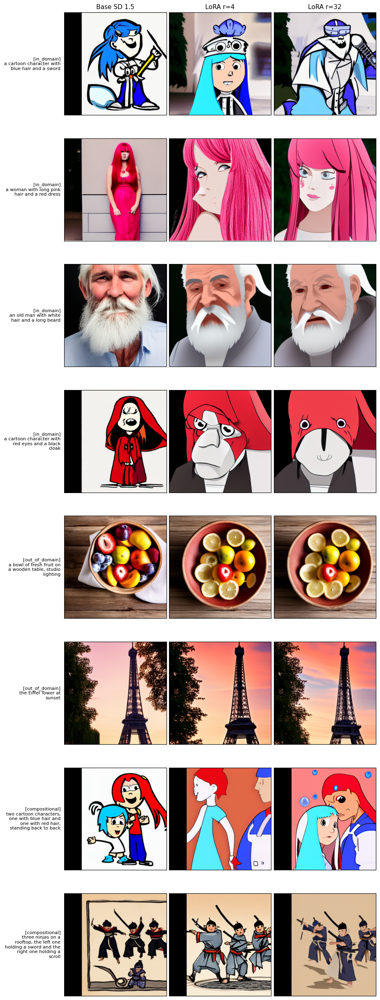

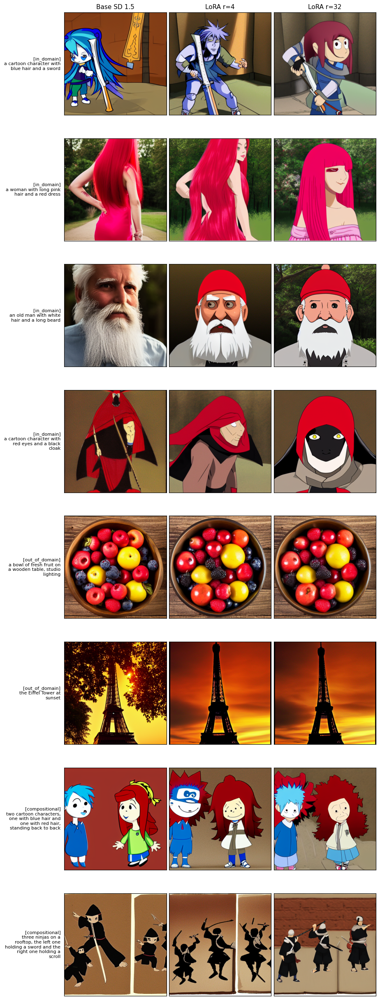

In [16]:
# CELL 16 - load all 120 images + side-by-side grids for 8 prompts (one grid per seed)
def load_images(model):
    return {(p["id"], s): Image.open(WORK / "images" / model / f"p{p['id']:02d}_s{s}.png").convert("RGB") for p in PROMPTS for s in SEEDS}
IM = {m: load_images(m) for m in MODELS}
print({m: len(v) for m, v in IM.items()}, "images per model")

GRID_IDS = [1, 3, 6, 9, 12, 14, 17, 19]      # 4 in-domain, 2 out-of-domain, 2 compositional - change freely
def make_grid(seed, ids, path):
    fig, axes = plt.subplots(len(ids), len(MODELS), figsize=(3.1 * len(MODELS), 3.1 * len(ids)), squeeze=False)
    for r, pid in enumerate(ids):
        for c, m in enumerate(MODELS):
            ax = axes[r, c]; ax.imshow(IM[m][(pid, seed)]); ax.set_xticks([]); ax.set_yticks([])
            if r == 0: ax.set_title(MODEL_LABELS[m], fontsize=11)
        axes[r, 0].set_ylabel(f"[{PROMPTS_BY_ID[pid]['category']}]\n" + textwrap.fill(PROMPTS_BY_ID[pid]["prompt"], 24),
                              rotation=0, ha="right", va="center", fontsize=8, labelpad=6)
    plt.tight_layout(); fig.savefig(path, dpi=130, bbox_inches="tight"); plt.show()
for s in SEEDS: make_grid(s, GRID_IDS, WORK / "grids" / f"grid_8prompts_seed{s}.png")

## 2.4 Evaluation, safety & documentation
Primary: **KID** vs the held-out test images and **CLIP score**. Secondary: **LPIPS diversity** between seeds. Efficiency: **GPU-hours per run, peak memory**. Human: blinded pairs. Safety: license, NSFW filter, memorization.

In [17]:
# CELL 17 - CLIP score (cosine(image, prompt) x 100, floored at 0 - same convention as torchmetrics)
from transformers import CLIPModel, CLIPProcessor
clip_model = CLIPModel.from_pretrained(CFG["clip_id"]).to(DEV).eval()
clip_proc  = CLIPProcessor.from_pretrained(CFG["clip_id"])

@torch.no_grad()
def clip_img_emb(pils, bs=32):
    out = []
    for i in range(0, len(pils), bs):
        px = clip_proc.image_processor([p.convert("RGB") for p in pils[i:i + bs]], return_tensors="pt")["pixel_values"].to(DEV)
        pooled = clip_model.vision_model(pixel_values=px).pooler_output
        out.append(F.normalize(clip_model.visual_projection(pooled).float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def clip_txt_emb(texts):
    t = clip_proc.tokenizer(texts, padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEV)
    pooled = clip_model.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output
    return F.normalize(clip_model.text_projection(pooled).float(), dim=-1).cpu()

T_EMB = dict(zip([p["id"] for p in PROMPTS], clip_txt_emb([p["prompt"] for p in PROMPTS])))
rows = []
for m in MODELS:
    keys = list(IM[m].keys()); E = clip_img_emb([IM[m][k] for k in keys])
    for k, e in zip(keys, E):
        p = PROMPTS_BY_ID[k[0]]
        rows.append(dict(model=m, pid=k[0], seed=k[1], category=p["category"], prompt=p["prompt"],
                         clip=float(100 * max(0.0, (e @ T_EMB[k[0]]).item()))))
df_clip = pd.DataFrame(rows)
print("CLIP score (higher = better prompt match), mean over images:")
print(df_clip.pivot_table(index="model", columns="category", values="clip", aggfunc="mean", margins=True, margins_name="ALL").loc[MODELS + ["ALL"]].round(3).to_string())
print("\nstd over the 40 images per model:\n", df_clip.groupby("model").clip.std().round(3).to_string())

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP score (higher = better prompt match), mean over images:
category  compositional  in_domain  out_of_domain     ALL
model                                                    
base             33.939     32.420         31.286  32.517
run_a            33.327     31.313         31.585  31.884
run_b            34.382     31.258         31.561  32.115
ALL              33.883     31.664         31.478  32.172

std over the 40 images per model:
 model
base     2.545
run_a    2.816
run_b    2.676


In [18]:
# CELL 18 - KID vs held-out TEST images  (lower = closer to the real data distribution)
from torchmetrics.image.kid import KernelInceptionDistance
def pil_u8(p): return torch.from_numpy(np.asarray(p.convert("RGB").resize((R, R)))).permute(2, 0, 1)
test_rows = [json.loads(l) for l in open(LOCAL / "data" / "test" / "metadata.jsonl")]
REAL = torch.stack([pil_u8(Image.open(LOCAL / "data" / "test" / r["file_name"])) for r in test_rows])
print("real (test) images:", tuple(REAL.shape))

def kid_score(fake_pils):
    n_sub = min(len(REAL), len(fake_pils)) // 2                      # subset_size must be < both sample counts
    m = KernelInceptionDistance(subset_size=n_sub, subsets=100, normalize=False).to(DEV)
    for i in range(0, len(REAL), 32): m.update(REAL[i:i + 32].to(DEV), real=True)
    fk = torch.stack([pil_u8(p) for p in fake_pils])
    for i in range(0, len(fk), 32): m.update(fk[i:i + 32].to(DEV), real=False)
    torch.manual_seed(SEED)
    mu, sd = m.compute()
    return float(mu), float(sd), n_sub

KID = {}
for m in MODELS:
    all_p = [IM[m][k] for k in IM[m]]
    ind_p = [IM[m][(p["id"], s)] for p in PROMPTS if p["category"] == "in_domain" for s in SEEDS]
    KID[m] = dict(all=kid_score(all_p), in_domain=kid_score(ind_p))
print("KID (mean +- std over 100 subsets; n_sub = subset size). With only 40 / 20 generated images, KID is noisy - say so in the report.")
for m in MODELS:
    a, i = KID[m]["all"], KID[m]["in_domain"]
    print(f"{MODEL_LABELS[m]:12s}  all-40: {a[0]:.4f} +- {a[1]:.4f} (n_sub={a[2]})   in-domain-20: {i[0]:.4f} +- {i[1]:.4f} (n_sub={i[2]})")

/tmp/ipykernel_792/3555458241.py:3: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  def pil_u8(p): return torch.from_numpy(np.asarray(p.convert("RGB").resize((R, R)))).permute(2, 0, 1)


real (test) images: (96, 3, 512, 512)


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:02<00:00, 33.4MB/s]


KID (mean +- std over 100 subsets; n_sub = subset size). With only 40 / 20 generated images, KID is noisy - say so in the report.
Base SD 1.5   all-40: 0.0623 +- 0.0135 (n_sub=20)   in-domain-20: 0.0609 +- 0.0242 (n_sub=10)
LoRA r=4      all-40: 0.0240 +- 0.0096 (n_sub=20)   in-domain-20: 0.0119 +- 0.0090 (n_sub=10)
LoRA r=32     all-40: 0.0171 +- 0.0079 (n_sub=20)   in-domain-20: 0.0062 +- 0.0082 (n_sub=10)


In [19]:
# CELL 19 - diversity: LPIPS between the seed-0 and seed-1 image of the SAME prompt (higher = more diverse)
import lpips
lp = lpips.LPIPS(net="alex", verbose=False).to(DEV).eval()
def to_lp(im): return torch.from_numpy(np.asarray(im.convert("RGB"))).permute(2, 0, 1).float().div(127.5).sub(1.0)
rows = []
for m in MODELS:
    for p in PROMPTS:
        a, b = to_lp(IM[m][(p["id"], SEEDS[0])]), to_lp(IM[m][(p["id"], SEEDS[1])])
        with torch.no_grad(): d = lp(a[None].to(DEV), b[None].to(DEV)).item()
        rows.append(dict(model=m, pid=p["id"], category=p["category"], lpips=d))
df_lp = pd.DataFrame(rows)
print(df_lp.pivot_table(index="model", columns="category", values="lpips", aggfunc="mean", margins=True, margins_name="ALL").loc[MODELS + ["ALL"]].round(4).to_string())

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:05<00:00, 45.3MB/s]


category  compositional  in_domain  out_of_domain     ALL
model                                                    
base             0.8432     0.8070         0.7413  0.7996
run_a            0.8379     0.7880         0.7430  0.7892
run_b            0.8202     0.7667         0.7663  0.7800
ALL              0.8338     0.7872         0.7502  0.7896


In [21]:
# CELL 20 - ONE results table (baseline = base SD1.5) + save
RESULTS = {}
for m in MODELS:
    r = dict(kid_all=KID[m]["all"][0], kid_all_std=KID[m]["all"][1], kid_in_domain=KID[m]["in_domain"][0], kid_in_domain_std=KID[m]["in_domain"][1])
    c = df_clip[df_clip.model == m]
    r["clip_all"] = float(c["clip"].mean())
    for cat in ["in_domain", "out_of_domain", "compositional"]: r[f"clip_{cat}"] = float(c[c.category == cat]["clip"].mean())
    l = df_lp[df_lp.model == m]
    r["lpips_diversity"] = float(l.lpips.mean())
    for cat in ["in_domain", "out_of_domain", "compositional"]: r[f"lpips_{cat}"] = float(l[l.category == cat].lpips.mean())
    r["gen_sec_per_image"] = float(GEN_TIMES.get(m, {}).get("sec_per_image", float("nan")))
    if m in RUNS:
        s = STATS[m]
        r.update(trainable_params_M=s["trainable_params"] / 1e6, train_gpu_hours=s["gpu_hours"], peak_mem_gib=s["peak_mem_allocated_gib"])
    else:
        r.update(trainable_params_M=float("nan"), train_gpu_hours=float("nan"), peak_mem_gib=float("nan"))
    RESULTS[m] = r
res_df = pd.DataFrame(RESULTS).T.rename(index=MODEL_LABELS)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print(res_df.round(4).T.to_string())
print("\ndirection: KID lower=better | CLIP higher=better | LPIPS diversity higher=more diverse | GPU-hours, peak memory lower=cheaper")
json.dump(RESULTS, open(WORK / "eval" / "p2_results.json", "w"), indent=1)
res_df.round(5).to_csv(WORK / "eval" / "p2_results.csv")

                     Base SD 1.5  LoRA r=4  LoRA r=32
kid_all                   0.0623    0.0240     0.0171
kid_all_std               0.0135    0.0096     0.0079
kid_in_domain             0.0609    0.0119     0.0062
kid_in_domain_std         0.0242    0.0090     0.0082
clip_all                 32.5165   31.8843    32.1147
clip_in_domain           32.4205   31.3125    31.2576
clip_out_of_domain       31.2865   31.5849    31.5613
clip_compositional       33.9388   33.3274    34.3822
lpips_diversity           0.7996    0.7892     0.7800
lpips_in_domain           0.8070    0.7880     0.7667
lpips_out_of_domain       0.7413    0.7430     0.7663
lpips_compositional       0.8432    0.8379     0.8202
gen_sec_per_image         4.3295    4.5364     4.5333
trainable_params_M           NaN    0.7972     6.3775
train_gpu_hours              NaN    0.5068     0.4868
peak_mem_gib                 NaN    4.5952     2.8755

direction: KID lower=better | CLIP higher=better | LPIPS diversity higher=more di

lowest CLIP scores among fine-tuned images:
 model  pid  seed      category  clip                                                   prompt
run_a   10     1     in_domain 26.17     a cartoon man with a scar on his face and a ponytail
run_b   11     1 out_of_domain 26.77 a photograph of a red sports car parked on a city street
run_a    9     0     in_domain 27.17      a cartoon character with red eyes and a black cloak
run_a   16     0 compositional 27.75                       a red cube on top of a blue sphere
run_b    3     0     in_domain 28.14              a woman with long pink hair and a red dress
run_b   10     1     in_domain 28.18     a cartoon man with a scar on his face and a ponytail
run_a   11     1 out_of_domain 28.20 a photograph of a red sports car parked on a city street
run_a    7     0     in_domain 28.65           a cartoon ninja standing on a rooftop at night

style-bleed proxy (zero-shot CLIP, out-of-domain prompts only):
  Base SD 1.5    0.0% of 10 OOD images look 

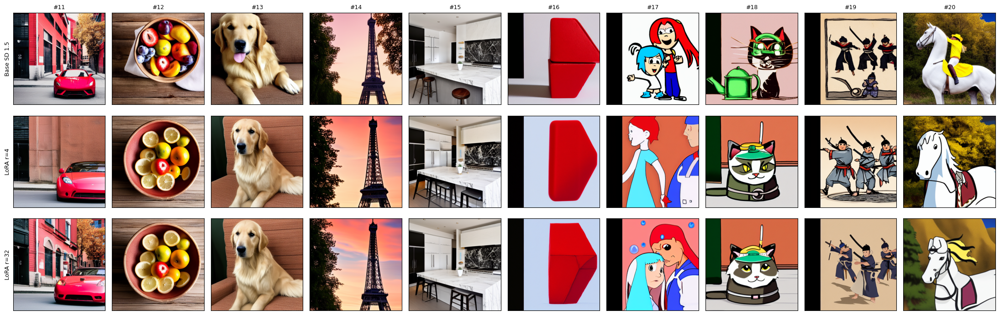

{11: 'a photograph of a red sports car parked on a city street', 12: 'a bowl of fresh fruit on a wooden table, studio lighting', 13: 'a golden retriever sitting on a sofa, photo', 14: 'the Eiffel Tower at sunset', 15: 'a modern kitchen interior with marble countertops', 16: 'a red cube on top of a blue sphere', 17: 'two cartoon characters, one with blue hair and one with red hair, standing back to back', 18: 'a cartoon cat wearing a tiny samurai helmet sitting next to a green teapot', 19: 'three ninjas on a rooftop, the left one holding a sword and the right one holding a scroll', 20: 'a cartoon character with a yellow hat riding a white horse in front of a mountain'}


In [22]:
# CELL 21 - material for your "two failure modes" write-up (YOU decide and describe them; this just surfaces evidence)
# (a) lowest-CLIP images of the fine-tuned runs
low = df_clip[df_clip.model != "base"].nsmallest(8, "clip")[["model", "pid", "seed", "category", "clip", "prompt"]]
print("lowest CLIP scores among fine-tuned images:\n", low.round(2).to_string(index=False))

# (b) style bleed proxy: on out-of-domain prompts, how often does CLIP call the image 'anime cartoon' rather than 'photograph'?
S_TXT = clip_txt_emb(["an anime-style cartoon illustration", "a realistic photograph"])
ood_ids = [p["id"] for p in PROMPTS if p["category"] == "out_of_domain"]
print("\nstyle-bleed proxy (zero-shot CLIP, out-of-domain prompts only):")
for m in MODELS:
    E = clip_img_emb([IM[m][(pid, s)] for pid in ood_ids for s in SEEDS])
    frac = float(((E @ S_TXT.T).argmax(1) == 0).float().mean())
    print(f"  {MODEL_LABELS[m]:12s} {100*frac:5.1f}% of {len(E)} OOD images look 'anime cartoon'")

# (c) every out-of-domain + compositional prompt, all models, seed 0 - look for style bleed / wrong counts / wrong colours
ids = [p["id"] for p in PROMPTS if p["category"] != "in_domain"]
fig, axes = plt.subplots(len(MODELS), len(ids), figsize=(2.2 * len(ids), 2.4 * len(MODELS)), squeeze=False)
for r_, m in enumerate(MODELS):
    for c_, pid in enumerate(ids):
        axes[r_, c_].imshow(IM[m][(pid, SEEDS[0])]); axes[r_, c_].set_xticks([]); axes[r_, c_].set_yticks([])
        if r_ == 0: axes[r_, c_].set_title(f"#{pid}", fontsize=9)
    axes[r_, 0].set_ylabel(MODEL_LABELS[m], fontsize=9)
plt.tight_layout(); fig.savefig(WORK / "grids" / "ood_and_compositional_seed0.png", dpi=130); plt.show()
print({pid: PROMPTS_BY_ID[pid]["prompt"] for pid in ids})

def show_prompt(pid):      # call show_prompt(16) etc. to inspect any prompt: rows = models, columns = seeds
    fig, ax = plt.subplots(len(MODELS), len(SEEDS), figsize=(3.2 * len(SEEDS), 3.2 * len(MODELS)), squeeze=False)
    for r_, m in enumerate(MODELS):
        for c_, s in enumerate(SEEDS):
            ax[r_, c_].imshow(IM[m][(pid, s)]); ax[r_, c_].axis("off"); ax[r_, c_].set_title(f"{MODEL_LABELS[m]} s{s}", fontsize=9)
    fig.suptitle(PROMPTS_BY_ID[pid]["prompt"], fontsize=10); plt.tight_layout(); plt.show()

### Human evaluation — blinded pairs (≥ 3 raters)


rubric: Which image is better overall: matches the text prompt AND looks like a clean, coherent image? Answer A, B, or T (tie).
A/B placement balance: {'base': 15, 'run_b': 10}
zip for raters: /content/p2_work/human_eval/pairs_for_raters.zip (18.7 MB) | answer key (keep private): /content/p2_work/eval/p2_human_key.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

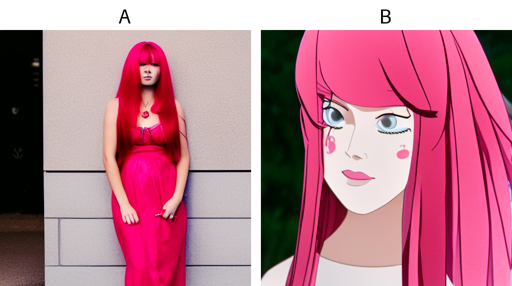

In [23]:
# CELL 22 (no-Drive version) - build 25 blinded pairs: baseline vs your chosen run, then zip them for the raters
FINAL_RUN = "run_b"                 # <- set to the run you pick after reading the results table (change and re-run to rebuild)
PAIR = ("base", FINAL_RUN)
RUBRIC = "Which image is better overall: matches the text prompt AND looks like a clean, coherent image? Answer A, B, or T (tie)."

from PIL import ImageDraw, ImageFont
try: font = ImageFont.load_default(size=40)
except TypeError: font = ImageFont.load_default()
pair_dir = WORK / "human_eval" / "pairs"; shutil.rmtree(pair_dir, ignore_errors=True); pair_dir.mkdir(parents=True)
rng_h = random.Random(SEED)
chosen = rng_h.sample([(p["id"], s) for p in PROMPTS for s in SEEDS], 25)
key_rows = []
for n, (pid, s) in enumerate(chosen, 1):
    left, right = PAIR if rng_h.random() < 0.5 else PAIR[::-1]
    canvas = Image.new("RGB", (2 * R + 20, R + 60), "white")
    canvas.paste(IM[left][(pid, s)], (0, 60)); canvas.paste(IM[right][(pid, s)], (R + 20, 60))
    d = ImageDraw.Draw(canvas); d.text((R // 2 - 15, 8), "A", fill="black", font=font); d.text((R + 20 + R // 2 - 15, 8), "B", fill="black", font=font)
    canvas.save(pair_dir / f"pair_{n:02d}.png")
    key_rows.append(dict(pair_id=n, prompt_id=pid, seed=s, prompt=PROMPTS_BY_ID[pid]["prompt"], A_model=left, B_model=right))
key = pd.DataFrame(key_rows)
key.to_csv(WORK / "eval" / "p2_human_key.csv", index=False)                   # the answer key: NOT inside the zip for raters
json.dump(dict(baseline=PAIR[0], final=PAIR[1], rubric=RUBRIC), open(WORK / "eval" / "p2_human_pair_models.json", "w"))
pd.DataFrame(dict(pair_id=key.pair_id, prompt=key.prompt, rater_1="", rater_2="", rater_3="")).to_csv(pair_dir / "ratings_template.csv", index=False)

# zip for the raters: 25 pair images + ratings_template.csv (no model names anywhere in it)
rater_zip = shutil.make_archive(str(WORK / "human_eval" / "pairs_for_raters"), "zip", pair_dir)
print("rubric:", RUBRIC)
print("A/B placement balance:", key.A_model.value_counts().to_dict())
print("zip for raters:", rater_zip, f"({Path(rater_zip).stat().st_size / 2**20:.1f} MB) | answer key (keep private):", WORK / "eval" / "p2_human_key.csv")
try:
    from google.colab import files
    files.download(rater_zip)
except Exception as e:
    print("auto-download not available - download the zip from the Files panel")
display(Image.open(pair_dir / "pair_01.png").resize((R, R // 2 + 30)))

In [26]:
# CELL 22b - upload the raters' filled CSV (columns: pair_id, prompt, rater_1, rater_2, rater_3)
from google.colab import files
up = files.upload()                                   # pick the CSV in the dialog
name = next(iter(up))
shutil.move(name, WORK / "eval" / "p2_human_ratings.csv")
print("saved ->", WORK / "eval" / "p2_human_ratings.csv"); print(pd.read_csv(WORK / "eval" / "p2_human_ratings.csv").head())

Saving ratings_template.csv to ratings_template.csv
saved -> /content/p2_work/eval/p2_human_ratings.csv
   pair_id                                             prompt  rater_1  rater_2  rater_3
0        1        a woman with long pink hair and a red dress      NaN      NaN      NaN
1        2  a cartoon cat wearing a tiny samurai helmet si...      NaN      NaN      NaN
2        3  a cartoon boy with spiky yellow hair and a for...      NaN      NaN      NaN
3        4  a modern kitchen interior with marble countertops      NaN      NaN      NaN
4        5     a cartoon ninja standing on a rooftop at night      NaN      NaN      NaN


### Safety analysis (≈ 1 page in the report): license · NSFW filter · memorization
License was printed in Cell 4 and the training-data NSFW filter ran in Cell 6. Below: the NSFW checker on all **generated** images, and a memorization check.

In [28]:
# CELL 24 - NSFW safety checker on every generated image (flags only; images are NOT altered for metrics)
SAFETY = dict(nsfw_by_model={}, nsfw_flagged={}, memorization_summary={})
for m in MODELS:
    keys = list(IM[m].keys()); fl = nsfw_flags([IM[m][k] for k in keys])
    SAFETY["nsfw_by_model"][m] = int(sum(fl)); SAFETY["nsfw_flagged"][m] = [list(k) for k, f in zip(keys, fl) if f]
free_checker()
print("generated images flagged by the SD safety checker:", SAFETY["nsfw_by_model"], "of", len(PROMPTS) * len(SEEDS), "per model")
print("flagged (prompt_id, seed):", SAFETY["nsfw_flagged"])
print("training data: removed", n_nsfw, "NSFW-flagged images in Cell 6 | dataset license:", DS_LICENSE or "NOT DECLARED")

config.json:   0%|          | 0.00/4.55k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


generated images flagged by the SD safety checker: {'base': 0, 'run_a': 1, 'run_b': 0} of 40 per model
flagged (prompt_id, seed): {'base': [], 'run_a': [[3, 1]], 'run_b': []}
training data: removed 264 NSFW-flagged images in Cell 6 | dataset license: NOT DECLARED


held-out TEST -> nearest TRAIN cosine: mean 0.904 | p99 0.966 | max 0.969   (what 'unseen but similar' looks like)
       mean_sim  max_sim  n_ge_tau  n_ge_0p95  min_lpips_to_nn
model                                                         
base      0.628    0.774         0          0            0.706
run_a     0.717    0.906         0          0            0.708
run_b     0.741    0.901         0          0            0.673
prompts identical to a training caption: ['a man with orange hair and a blue shirt']


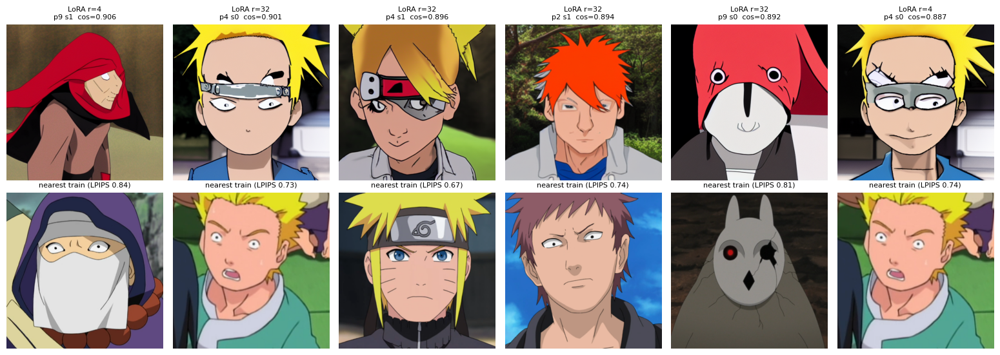

In [29]:
# CELL 25 - memorization check: nearest TRAIN image (CLIP cosine) for every generated image, calibrated against held-out TEST images
def embed_paths(paths, bs=64):
    return torch.cat([clip_img_emb([Image.open(p).convert("RGB") for p in paths[i:i + bs]]) for i in range(0, len(paths), bs)])
tr_rows  = [json.loads(l) for l in open(LOCAL / "data" / "train" / "metadata.jsonl")]
tr_paths = [LOCAL / "data" / "train" / r["file_name"] for r in tr_rows]
TR_EMB = embed_paths(tr_paths)
TE_EMB = embed_paths([LOCAL / "data" / "test" / r["file_name"] for r in test_rows])
nn_test = (TE_EMB @ TR_EMB.T).max(1).values.numpy()
TAU = float(np.percentile(nn_test, 99))
print(f"held-out TEST -> nearest TRAIN cosine: mean {nn_test.mean():.3f} | p99 {TAU:.3f} | max {nn_test.max():.3f}   (what 'unseen but similar' looks like)")

rows = []
for m in MODELS:
    keys = list(IM[m].keys()); E = clip_img_emb([IM[m][k] for k in keys])
    sim, nn = (E @ TR_EMB.T).max(1)
    for k, s_, j in zip(keys, sim.tolist(), nn.tolist()):
        with torch.no_grad():
            d = lp(to_lp(IM[m][k])[None].to(DEV), to_lp(Image.open(tr_paths[j]).convert("RGB"))[None].to(DEV)).item()
        rows.append(dict(model=m, pid=k[0], seed=k[1], nn_sim=s_, nn_train=j, lpips_to_nn=d))
mem = pd.DataFrame(rows)
summ = mem.groupby("model").agg(mean_sim=("nn_sim", "mean"), max_sim=("nn_sim", "max"),
                                n_ge_tau=("nn_sim", lambda x: int((x >= TAU).sum())), n_ge_0p95=("nn_sim", lambda x: int((x >= 0.95).sum())),
                                min_lpips_to_nn=("lpips_to_nn", "min")).loc[MODELS]
print(summ.round(3).to_string())
for m in MODELS:
    r = summ.loc[m]
    SAFETY["memorization_summary"][m] = (f"{int(r.n_ge_tau)} of {len(PROMPTS)*len(SEEDS)} generated images have nearest-train CLIP cosine >= {TAU:.3f} "
                                         f"(99th pct of held-out test images); max {r.max_sim:.3f}; min LPIPS to nearest train image {r.min_lpips_to_nn:.3f}")
exact = [p["prompt"] for p in PROMPTS if p["prompt"].lower() in {r["text"].lower() for r in tr_rows}]
print("prompts identical to a training caption:", exact)

top = mem[mem.model != "base"].nlargest(6, "nn_sim")
fig, ax = plt.subplots(2, len(top), figsize=(2.6 * len(top), 5.6), squeeze=False)
for c_, (_, r) in enumerate(top.iterrows()):
    ax[0, c_].imshow(IM[r.model][(int(r.pid), int(r.seed))]); ax[0, c_].set_title(f"{MODEL_LABELS[r.model]}\np{int(r.pid)} s{int(r.seed)}  cos={r.nn_sim:.3f}", fontsize=8)
    ax[1, c_].imshow(Image.open(tr_paths[int(r.nn_train)])); ax[1, c_].set_title(f"nearest train (LPIPS {r.lpips_to_nn:.2f})", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); fig.savefig(WORK / "grids" / "memorization_top6.png", dpi=130); plt.show()
json.dump(SAFETY, open(WORK / "eval" / "p2_safety.json", "w"), indent=1)

## Final push — model cards with results + all images
Re-generates both model cards (now with the evaluation + safety numbers) and uploads all 120 images, grids and `prompts.json` to a Hugging Face dataset repo.

In [30]:
# CELL 26 - final HF push: updated model cards + images dataset
def push_images_dataset():
    if not api: print("no HF_TOKEN -> skipped"); return
    stage = LOCAL / "hf_stage" / "images"; shutil.rmtree(stage, ignore_errors=True); stage.mkdir(parents=True)
    shutil.copytree(WORK / "images", stage / "images"); shutil.copytree(WORK / "grids", stage / "grids")
    shutil.copy(WORK / "eval" / "p2_prompts.json", stage / "prompts.json"); shutil.copy(WORK / "eval" / "p2_results.json", stage / "results.json")
    (stage / "README.md").write_text("\n".join([
        "---", "license: creativeml-openrail-m", "tags:", "- stable-diffusion", "- generated-images", "---", "",
        f"# {HF_PREFIX}-images", "",
        "Generated images for DATA 266 Lab 2 Part 2: 20 fixed prompts x seeds 0,1 for the base SD1.5 model and each fine-tuned LoRA run.", "",
        "- `images/<model>/pXX_sY.png` - prompt id XX, seed Y; `base`, `run_a`, `run_b`",
        "- `prompts.json` - the 20 prompts (10 in-domain, 5 out-of-domain, 5 compositional), sampler settings",
        "- `grids/` - side-by-side grids, loss curves, memorization figure; `results.json` - metrics table", "",
        f"Models: " + ", ".join(f"`{HF_USER}/{HF_PREFIX}-{n}` ({RUNS[n]['label']})" for n in RUNS)]))
    repo = f"{HF_USER}/{HF_PREFIX}-images"
    api.create_repo(repo, repo_type="dataset", private=HF_PRIVATE, exist_ok=True)
    api.upload_folder(folder_path=str(stage), repo_id=repo, repo_type="dataset", commit_message="generated images + grids")
    print("pushed ->", f"https://huggingface.co/datasets/{repo}")

for n in RUNS: push_model(n)          # model cards now include RESULTS + SAFETY
push_images_dataset()

pushed -> https://huggingface.co/muhammadfsalman/data266-lab2-p2-run_a (private)
pushed -> https://huggingface.co/muhammadfsalman/data266-lab2-p2-run_b (private)
pushed -> https://huggingface.co/datasets/muhammadfsalman/data266-lab2-p2-images


In [31]:
# CELL 27 - pinned requirements actually used + list of files to copy into your repo
from importlib.metadata import version, PackageNotFoundError
pkgs = ["torch", "torchvision", "diffusers", "transformers", "peft", "accelerate", "datasets", "huggingface_hub", "safetensors",
        "torchmetrics", "torch-fidelity", "lpips", "imagehash", "Pillow", "numpy", "pandas", "scipy", "matplotlib", "tqdm"]
lines = []
for p in pkgs:
    try: lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError: pass
(WORK / "eval" / "requirements_p2.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nCopy into your repo (eval/ and root), then commit + tag p2-v1.0:")
for f in sorted((WORK / "eval").glob("*")): print("  ", f)
print("   ", WORK / "grids", "(figures for the report)")

torch==2.14.1+cu130
torchvision==0.29.1+cu130
diffusers==0.42.1
transformers==5.22.1
peft==0.21.2
accelerate==1.15.0
datasets==4.8.5
huggingface_hub==1.33.0
safetensors==0.8.0
torchmetrics==1.9.0
torch-fidelity==0.4.0
lpips==0.1.4
imagehash==4.3.2
Pillow==11.3.0
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
matplotlib==3.10.0
tqdm==4.67.3

Copy into your repo (eval/ and root), then commit + tag p2-v1.0:
   /content/p2_work/eval/p2_config.json
   /content/p2_work/eval/p2_data_prep.json
   /content/p2_work/eval/p2_human_key.csv
   /content/p2_work/eval/p2_human_pair_models.json
   /content/p2_work/eval/p2_human_ratings.csv
   /content/p2_work/eval/p2_prompts.json
   /content/p2_work/eval/p2_results.csv
   /content/p2_work/eval/p2_results.json
   /content/p2_work/eval/p2_safety.json
   /content/p2_work/eval/requirements_p2.txt
    /content/p2_work/grids (figures for the report)


In [32]:
# CELL D - zip + download everything from the Part 2 notebook (two zips so a slow big one cannot block the small one)
import zipfile
from pathlib import Path
from google.colab import files

INCLUDE_CHECKPOINT = True          # cleaned data + latents (~0.7 GB). False = skip the second zip
OUT = Path("/content/p2_downloads"); OUT.mkdir(exist_ok=True)

def zip_dir(src, dst, skip=()):
    n = 0
    with zipfile.ZipFile(dst, "w", zipfile.ZIP_DEFLATED, compresslevel=1) as z:
        for p in sorted(Path(src).rglob("*")):
            rel = p.relative_to(src)
            if p.is_file() and not any(part in skip for part in rel.parts):
                z.write(p, Path("data266_lab2_p2") / rel); n += 1
    return n

def size_mb(p): return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 2**20

print("what is in", WORK)
for d in sorted(WORK.iterdir()): print(f"  {d.name:14s} {size_mb(d) if d.is_dir() else d.stat().st_size / 2**20:8.1f} MB")

jobs = [("data266_lab2_p2_results.zip", ("checkpoint",))]
if INCLUDE_CHECKPOINT and (WORK / "checkpoint").exists():
    jobs.append(("data266_lab2_p2_checkpoint.zip", tuple(d.name for d in WORK.iterdir() if d.name != "checkpoint")))
for name, skip in jobs:
    dst = OUT / name; k = zip_dir(WORK, dst, skip)
    print(f"{name}: {k} files, {dst.stat().st_size / 2**20:.1f} MB -> downloading (allow multiple downloads if your browser asks)")
    files.download(str(dst))

what is in /content/p2_work
  checkpoint        353.5 MB
  eval                0.0 MB
  grids              12.9 MB
  human_eval         37.4 MB
  images             44.7 MB
  runs               27.5 MB
data266_lab2_p2_results.zip: 167 files, 120.6 MB -> downloading (allow multiple downloads if your browser asks)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

data266_lab2_p2_checkpoint.zip: 3 files, 337.4 MB -> downloading (allow multiple downloads if your browser asks)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>